<a href="https://colab.research.google.com/github/gozdekorkut/double-descent-reproduction/blob/main/notebooks/03_relu_1d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 — Why more features give a *smoother* interpolant (1-D random ReLU features)

Reproduces **Figure 3** of Belkin et al. (2019).

**Setting.** n = 10 training points $(x_i, y_i)$ with $x_i \in [-3, 3]$. Random ReLU features
$\phi_k(x) = \frac{1}{\sqrt N}\max(v_{k1} x + v_{k2},\, 0)$, with $(v_{k1}, v_{k2})$ uniform on the unit circle (paper Appendix C.2).
The model is $h(x) = \sum_{k=1}^N a_k \phi_k(x)$, fitted by **minimum-norm least squares**, exactly as in notebook 01.

**What to look for.**

- With N = 40 the fit passes through every point but is bumpy (kinks between the points).
- With N = 4,000 it passes through every point **and** is smooth, with a much smaller norm.

All three fit the training data perfectly, so training error cannot tell them apart. The minimum-norm choice with many features picks the "simplest" curve; this is the paper's explanation of the second descent (Occam's razor).

**About the data.** The paper does not give its 10 points. We draw $x_i$ uniformly in [−3, 3] and set $y_i = f(x_i) + \varepsilon_i$ with $f(x) = 3\sin(1.5x) + x$ and Gaussian noise of standard deviation 1. The function $f$ also lets us measure test error in section 5.

**About the norm.** The paper reports the norm "scaled by √N" (≈ 695 for N = 40, ≈ 159 for N = 4,000). Our features already include the $1/\sqrt N$ factor, so our $\|a\|$ is that scaled norm. Exact values will differ because the data differ; what should match is the **direction**: much smaller norm for N = 4,000.

No GPU needed: this notebook runs in seconds on CPU.

## 1. Settings

In [1]:
N_POINTS = 10                      # paper: 10 data points
N_SHOW = [40, 4000]                # fits to draw (same as the paper)
N_CHECK = [10, 20, 40, 100, 400, 1000, 4000]
FEATURE_SEEDS = list(range(20))    # 20 independent draws of the random features for the sweep
DATA_SEED = 0
NOISE_STD = 1.0

DRIVE_DIR = "/content/drive/MyDrive/double-descent"
RESULTS_CSV = f"{DRIVE_DIR}/results/relu_1d_norms.csv"

## 2. Setup

In [2]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
for sub in ["results", "figures"]:
    os.makedirs(f"{DRIVE_DIR}/{sub}", exist_ok=True)

DTYPE = torch.float64

Mounted at /content/drive


## 3. Data, features and the minimum-norm fit

`torch.linalg.lstsq(..., driver="gelsd")` solves least squares through the SVD. When the system has many solutions ($N > n$) it returns the one with the **smallest norm**, i.e. $a = \Phi^+ y$ (same solution as notebook 01, section 4).

In [3]:
def target(x):
    return 3 * torch.sin(1.5 * x) + x

g = torch.Generator().manual_seed(DATA_SEED)
x_train = 6 * torch.rand(N_POINTS, generator=g, dtype=DTYPE) - 3
y_train = target(x_train) + NOISE_STD * torch.randn(N_POINTS, generator=g, dtype=DTYPE)
x_grid = torch.linspace(-3, 3, 1000, dtype=DTYPE)

def relu_features(x, V):
    # x: (m,), V: (2, N) with columns on the unit circle  ->  (m, N)
    X = torch.stack([x, torch.ones_like(x)], dim=1)       # (m, 2): the input and a constant 1 for the bias
    return torch.relu(X @ V) / np.sqrt(V.shape[1])

def sample_V(N, seed):
    g = torch.Generator().manual_seed(seed)
    V = torch.randn(2, N, generator=g, dtype=DTYPE)
    return V / V.norm(dim=0, keepdim=True)                # normalise each column -> uniform on the unit circle

def fit(N, seed):
    V = sample_V(N, seed)
    Phi = relu_features(x_train, V)
    a = torch.linalg.lstsq(Phi, y_train[:, None], driver="gelsd").solution[:, 0]
    h = lambda x: relu_features(x, V) @ a
    return h, a.norm().item()

## 4. Figure 3: the fitted functions

N =    40   norm =    236.74   train MSE = 5.31e-29
N =  4000   norm =    162.51   train MSE = 1.57e-27


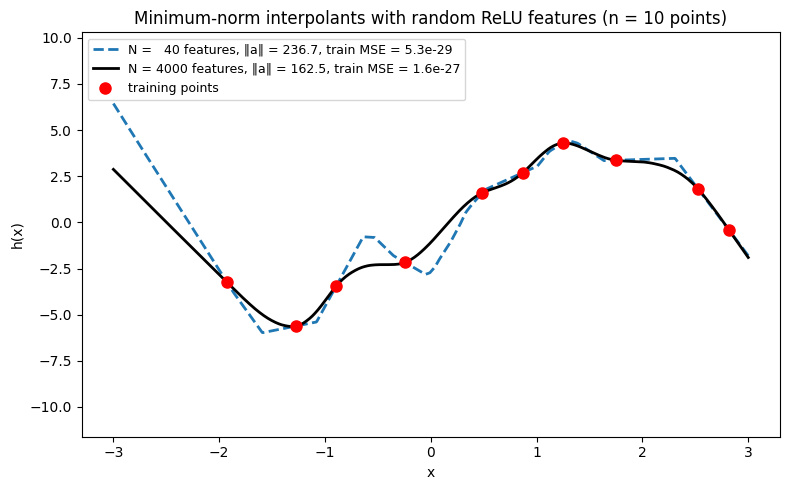

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
styles = {40: ("C0", "--"), 4000: ("k", "-")}
for N in N_SHOW:
    h, norm = fit(N, seed=0)
    color, ls = styles.get(N, (None, "-"))
    train_mse = ((h(x_train) - y_train) ** 2).mean().item()
    ax.plot(x_grid, h(x_grid), color=color, ls=ls, lw=2,
            label=f"N = {N:>4} features, ‖a‖ = {norm:.1f}, train MSE = {train_mse:.1e}")
    print(f"N = {N:5d}   norm = {norm:9.2f}   train MSE = {train_mse:.2e}")
ax.plot(x_train, y_train, "o", color="red", ms=8, label="training points")
ax.set_ylim(y_train.min().item() - 6, y_train.max().item() + 6)
ax.set_xlabel("x"); ax.set_ylabel("h(x)")
ax.set_title("Minimum-norm interpolants with random ReLU features (n = 10 points)")
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
for ext in ["pdf", "png"]:
    fig.savefig(f"{DRIVE_DIR}/figures/relu_1d_fits.{ext}", dpi=150)
plt.show()

## 5. Is it a lucky draw? Norm over 20 random draws

The picture above uses one draw of the features. Here we repeat the fit for 20 independent draws and report the median norm, the median test error (mean squared distance to the true function $f$ on 1,000 points), and whether the fit interpolates.

**Why N = 10 does not interpolate here.** In one dimension a ReLU feature whose kink lies outside the data range is just a straight line over the data, and all straight lines together span only 2 directions. So 10 random features give fewer than 10 independent directions (the `rank` column) and cannot fit 10 points exactly. In 784-dimensional MNIST this does not happen, which is why notebook 01 interpolates exactly at N = n.

In [5]:
f_grid = target(x_grid)
rows = []
for N in N_CHECK:
    for seed in FEATURE_SEEDS:
        h, norm = fit(N, seed)
        rank = torch.linalg.matrix_rank(relu_features(x_train, sample_V(N, seed))).item()
        rows.append(dict(N=N, seed=seed, norm=norm, rank=rank,
                         train_mse=((h(x_train) - y_train) ** 2).mean().item(),
                         test_mse=((h(x_grid) - f_grid) ** 2).mean().item()))
res = pd.DataFrame(rows)
res["interpolates"] = res.train_mse < 1e-6
res.to_csv(RESULTS_CSV, index=False)
table = res.groupby("N").agg(median_norm=("norm", "median"), median_test_mse=("test_mse", "median"),
                             median_rank=("rank", "median"), share_interpolating=("interpolates", "mean"))
display(table.round(3))

,median_norm,median_test_mse,median_rank,share_interpolating
N,,,,
10,156.826,2.207,7.0,0.00
20,271.495,1.877,10.0,0.60
40,216.596,1.112,10.0,0.85
100,179.139,1.090,10.0,1.00
400,174.092,0.974,10.0,1.00
1000,162.675,1.021,10.0,1.00
4000,162.437,0.993,10.0,1.00
